In [ ]:
import tensorflow as tf
import tensorflow_hub as hub
import tf_keras as tfk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import Image
from sklearn.model_selection import train_test_split
from matplotlib.pyplot import imread

In [ ]:
import tensorflow as tf
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  print('GPU не знайдено. Перевірте налаштування.')
else:
  print('Знайдено GPU за адресою: {}'.format(device_name))

Знайдено GPU за адресою: /device:GPU:0


# Collecting data

In [ ]:
filenames_n = ["/content/drive/MyDrive/pneumonia/train/NORMAL/" + fname for fname in os.listdir("/content/drive/MyDrive/pneumonia/train/NORMAL")]
filenames_p = ["/content/drive/MyDrive/pneumonia/train/PNEUMONIA/" + fname for fname in os.listdir("/content/drive/MyDrive/pneumonia/train/PNEUMONIA")]
filenames = filenames_n + filenames_p

In [ ]:
len(filenames_n), len(filenames_p)

(1341, 3875)

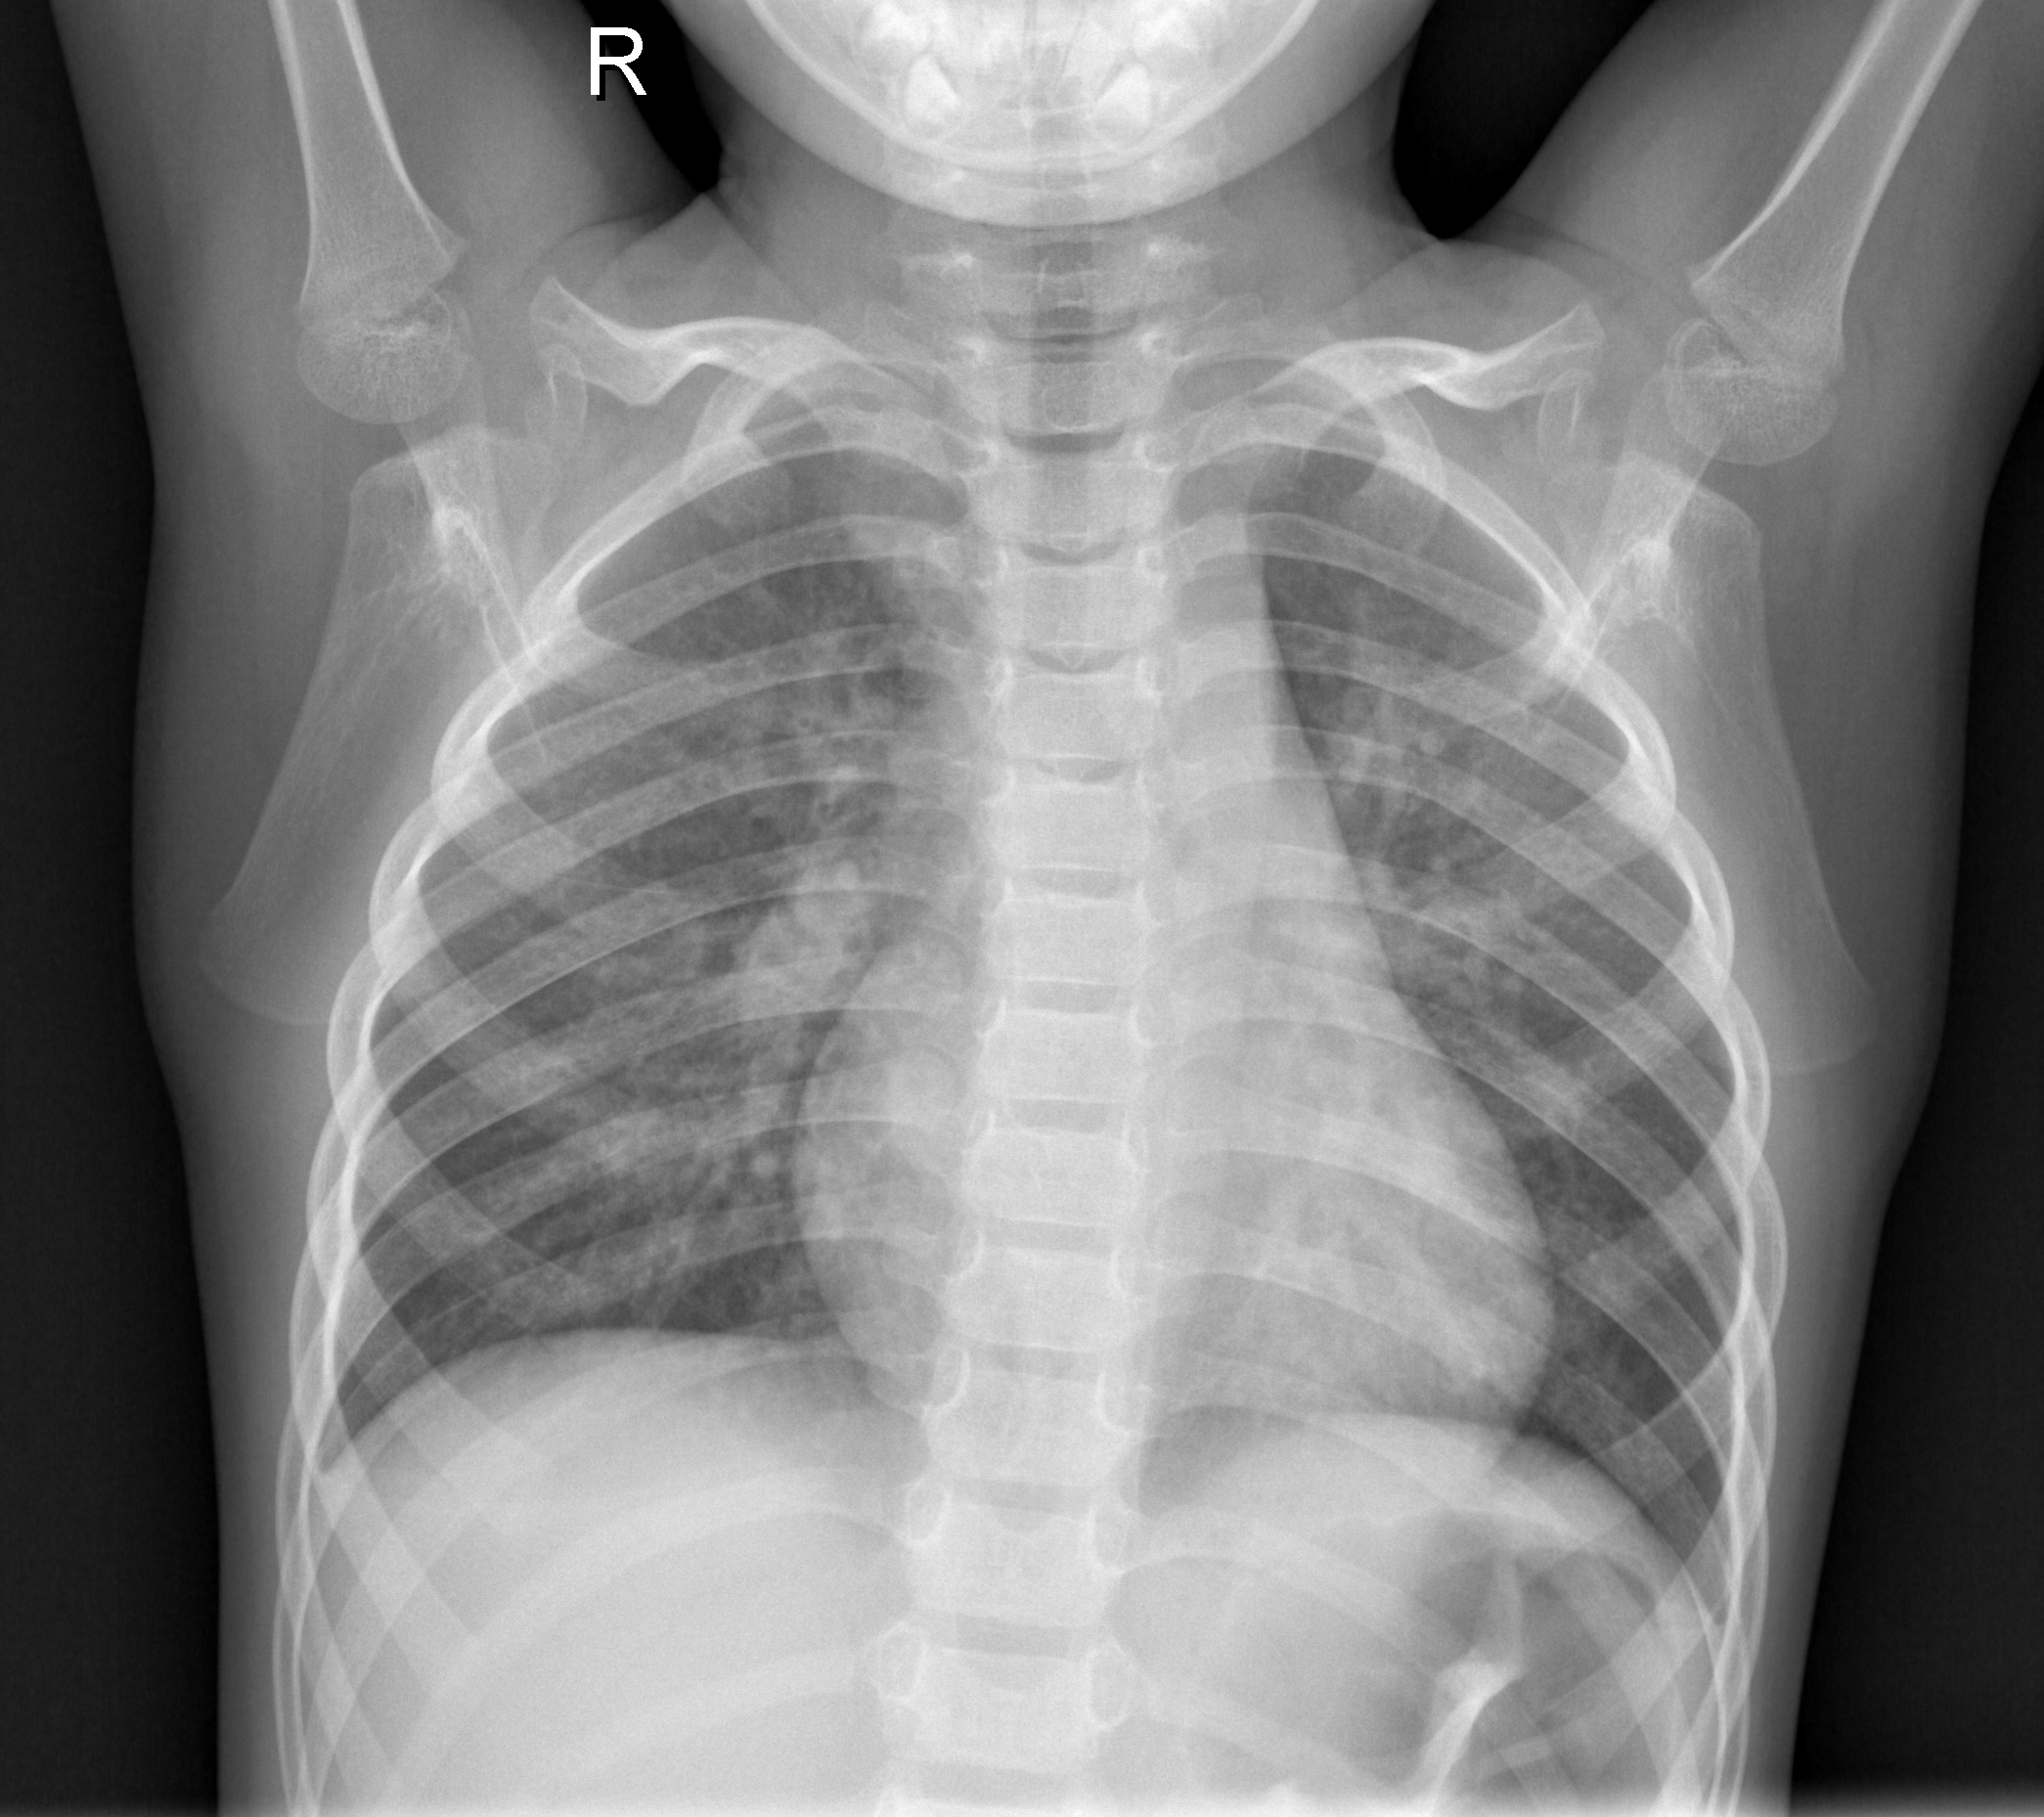

In [ ]:
Image("/content/drive/MyDrive/pneumonia/train/NORMAL/IM-0115-0001.jpeg")

In [ ]:
train_n_ids = ['normal' for image in filenames_n]
train_p_ids = ['pneumonia' for image in filenames_p]
train_n_ids[0], train_p_ids[0],

('normal', 'pneumonia')

In [ ]:
train_ids = train_n_ids + train_p_ids

In [ ]:
labels = np.array(train_ids)
labels

array(['normal', 'normal', 'normal', ..., 'pneumonia', 'pneumonia',
       'pneumonia'], dtype='<U9')

In [ ]:
classes = np.unique(labels)
classes

array(['normal', 'pneumonia'], dtype='<U9')

In [ ]:
labels[0] == classes

array([ True, False])

In [ ]:
boolean_labels = [label == classes for label in labels]

# Creating a validation set


In [ ]:
X = filenames
y = boolean_labels
NUM_IMAGES = 1000

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X[:NUM_IMAGES], y[:NUM_IMAGES], test_size=0.2)
len(X_train), len(y_train), len(X_val), len(y_val)

(800, 800, 200, 200)

# Preprocessing images

In [ ]:
image = imread(filenames[44])
image.shape

(1445, 1746)

In [ ]:
IMG_SIZE = 224
def process_image(image_path, img=IMG_SIZE):
  """
  Turns the image into a Tensor.
  """
  image = tf.io.read_file(image_path)
  image = tf.image.decode_jpeg(image, channels=3)
  image = tf.image.convert_image_dtype(image, tf.float32)
  image = tf.image.resize(image, size = [IMG_SIZE, IMG_SIZE])

  return image

# Turning data into batch

In [ ]:
def get_image_label(image_path, label):
  return process_image(image_path), label

In [ ]:
BATCH_SIZE = 32
def create_data_batches(X, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):
  if test_data:
    print("Creating test data batches...")
    data = tf.data.Dataset.from_tensor_slices((tf.constant(X)))
    data_batch = data.map(process_image).batch(BATCH_SIZE)
    return data_batch
  elif valid_data:
    print("Creating validation data batches...")
    data = tf.data.Dataset.from_tensor_slices((tf.constant(X),
                                               tf.constant(y)))
    data_batch = data.map(get_image_label).batch(BATCH_SIZE)
    return data_batch
  else:
    print("Creating training data batches...")
    data = tf.data.Dataset.from_tensor_slices((tf.constant(X),
                                               tf.constant(y)))
    data = data.shuffle(buffer_size=len(X))
    data = data.map(get_image_label)
    data_batch = data.batch(BATCH_SIZE)
  return data_batch

In [ ]:
train_data = create_data_batches(X_train, y_train)
val_data = create_data_batches(X_val, y_val, valid_data=True)

Creating training data batches...
Creating validation data batches...


In [ ]:
train_data.element_spec, val_data.element_spec

((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 2), dtype=tf.bool, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 2), dtype=tf.bool, name=None)))

In [ ]:
def show_25_images(images, labels):
  plt.figure(figsize=(10,10))
  for i in range(25):
    ax = plt.subplot(5, 5, i+1)
    plt.imshow(images[i])
    plt.title(classes[labels[i].argmax()])
    plt.axis("off")

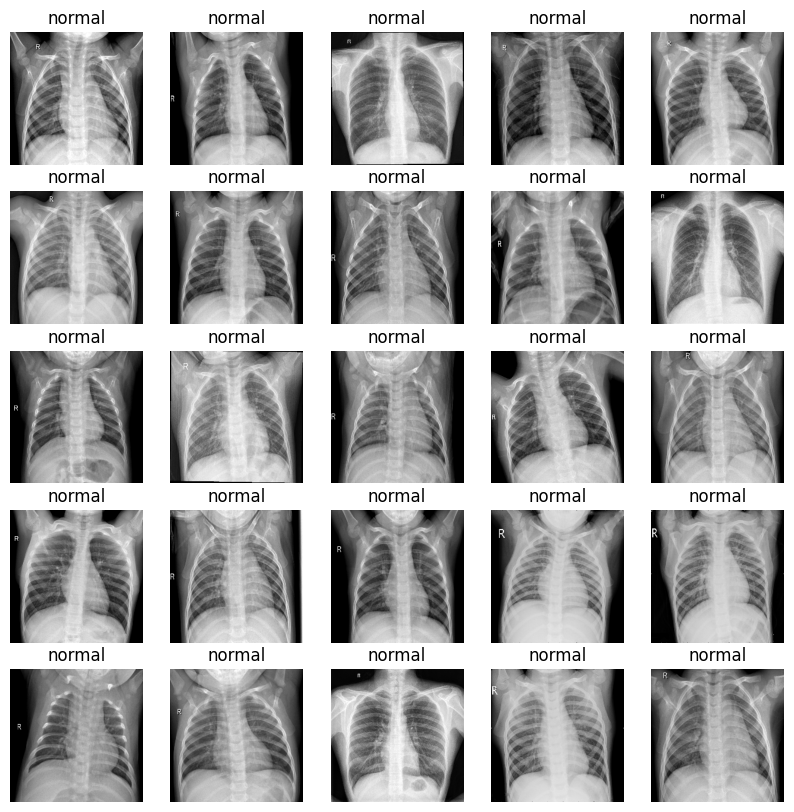

In [ ]:
train_images, train_labels = next(train_data.as_numpy_iterator())
show_25_images(train_images, train_labels)

In [ ]:
INPUT_SHAPE = [None, IMG_SIZE, IMG_SIZE, 3]
OUTPUT_SHAPE = len(classes)
MODEL_URL = "https://www.kaggle.com/models/google/mobilenet-v2/tensorFlow2/130-224-classification/2"

In [ ]:
def create_model(input_shape=INPUT_SHAPE, output_shape = OUTPUT_SHAPE, model_url=MODEL_URL):
  print("Building model with:", MODEL_URL)

  model = tfk.Sequential([
      hub.KerasLayer(MODEL_URL),
      tfk.layers.Dense(units=OUTPUT_SHAPE,
                       activation="sigmoid")
  ])

  model.compile(
      loss=tfk.losses.BinaryCrossentropy(),
      optimizer=tfk.optimizers.Adam(),
      metrics=["accuracy"]
  )

  model.build(INPUT_SHAPE)

  return model

In [ ]:
model = create_model()
model.summary()

Building model with: https://www.kaggle.com/models/google/mobilenet-v2/tensorFlow2/130-224-classification/2
Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer_2 (KerasLayer)  (None, 1001)              5432713   
                                                                 
 dense_2 (Dense)             (None, 2)                 2004      
                                                                 
Total params: 5434717 (20.73 MB)
Trainable params: 2004 (7.83 KB)
Non-trainable params: 5432713 (20.72 MB)
_________________________________________________________________


# Creating callbacks

In [ ]:
%load_ext tensorboard

In [ ]:
import datetime
def create_tensorboard_callback():
  logdir = os.path.join("drive/MyDrive/Pneumonia/logs",
                        datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
  return tfk.callbacks.TensorBoard(logdir)

early_stopping = tfk.callbacks.EarlyStopping(monitor="val_accuracy",
                                             patience = 3)

# Training a model

In [ ]:
NUM_EPOCHS = 100
def train_model():
  """
  Trains a given model and returns the trained version of it.
  """
  model = create_model()
  tensorboard = create_tensorboard_callback()
  model.fit(x = train_data,
            epochs = NUM_EPOCHS,
            validation_data = val_data,
            validation_freq = 1,
            callbacks= [tensorboard, early_stopping])
  return model

In [ ]:
model = train_model()

Building model with: https://www.kaggle.com/models/google/mobilenet-v2/tensorFlow2/130-224-classification/2
Epoch 1/100
25/25 [==============================] - 236s 9s/step - loss: 0.1003 - accuracy: 0.9563 - val_loss: 4.0381e-04 - val_accuracy: 1.0000
Epoch 2/100
25/25 [==============================] - 73s 3s/step - loss: 2.1831e-04 - accuracy: 1.0000 - val_loss: 1.7905e-04 - val_accuracy: 1.0000
Epoch 3/100
25/25 [==============================] - 74s 3s/step - loss: 1.5068e-04 - accuracy: 1.0000 - val_loss: 1.6177e-04 - val_accuracy: 1.0000
Epoch 4/100
25/25 [==============================] - 88s 3s/step - loss: 1.4193e-04 - accuracy: 1.0000 - val_loss: 1.5587e-04 - val_accuracy: 1.0000


In [ ]:
val_preds = model.predict(val_data, verbose=1)
val_preds

7/7 [==============================] - 21s 2s/step


array([[9.99906480e-01, 5.24488605e-05],
       [9.99931574e-01, 1.82296080e-05],
       [9.99931276e-01, 6.97083233e-05],
       [9.99871135e-01, 4.42866527e-04],
       [9.99762297e-01, 1.78902832e-04],
       [9.99985993e-01, 1.85114550e-05],
       [9.99965787e-01, 5.83958608e-05],
       [9.99907851e-01, 4.91399114e-05],
       [9.99928474e-01, 2.09635309e-05],
       [9.99909520e-01, 3.07492191e-05],
       [9.99966025e-01, 3.27462476e-05],
       [9.99918461e-01, 7.37061782e-05],
       [9.99814808e-01, 3.02253844e-04],
       [9.99969244e-01, 8.29787532e-05],
       [9.99956965e-01, 5.33673119e-05],
       [9.99972105e-01, 2.61287514e-05],
       [9.96966243e-01, 8.91932403e-04],
       [9.99918103e-01, 1.24271410e-05],
       [9.99867141e-01, 4.98401176e-04],
       [9.99599636e-01, 2.19965747e-04],
       [9.99480903e-01, 6.93768015e-05],
       [9.99808431e-01, 1.61076357e-04],
       [9.99812841e-01, 3.18846782e-04],
       [9.99915898e-01, 1.06734806e-04],
       [9.996665

In [ ]:
def get_pred_label(preds):
  """
  Turns an array of prediction probabilities into a label.
  """
  return classes[np.argmax(preds)]

In [ ]:
def unbatchify(data):
  """
  Takes a batched dataset of (image, label) Tensors and returns arrays of images and labels.
  """
  images = []
  labels = []
  for image, label in data.unbatch().as_numpy_iterator():
    images.append(image)
    labels.append(classes[np.argmax(label)])
  return images, labels


In [ ]:
val_images, val_labels = unbatchify(val_data)

KeyboardInterrupt: 

# Visualising predictions

In [ ]:
def plot_pred(preds, labels, images, n=1):
  """
  View the prediction, ground truth and image for sample n
  """
  pred_prob, true_label, image = preds[n], labels[n], images[n]
  pred_label = get_pred_label(pred_prob)

  plt.imshow(image)
  plt.xticks([])
  plt.yticks([])

  if pred_label == true_label:
    color = "green"
  else:
    color = "red"

  plt.title("{} {:2.0f}% {}".format(pred_label,
                                   np.max(pred_prob)*100,
                                   true_label),
                                   color=color)

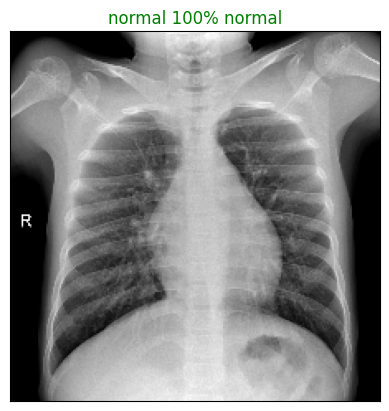

In [ ]:
plot_pred(val_preds, val_labels, val_images, 120)

# Saving and loading a model

In [ ]:
def save_model(model, suffix=None):
  modeldir = os.path.join("drive/MyDrive/Pneumonia/models",
                          datetime.datetime.now().strftime("%Y%m%d-%H%H%s"))
  model_path = modeldir + "-" + suffix + ".h5"
  print(f"Saving model to: {model_path}...")
  model.save(model_path)
  return model_path

In [ ]:
def load_model(model_path):
  print(f"Loading saved model from: {model_path}...")
  model = tfk.models.load_model(model_path,
                                custom_objects={"KerasLayer": hub.KerasLayer})
  return model

# Training the final model (full data)

In [ ]:
len(X), len(y)

(5216, 5216)

In [ ]:
full_data = create_data_batches(X, y)

Creating training data batches...


In [ ]:
full_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 2), dtype=tf.bool, name=None))>

In [ ]:
full_model = create_model()

Building model with: https://www.kaggle.com/models/google/mobilenet-v2/tensorFlow2/130-224-classification/2


In [ ]:
full_model_tensorboard = create_tensorboard_callback()
full_model_early_stopping = tfk.callbacks.EarlyStopping(monitor="accuracy",
                                                        patience=3)
full_model.fit(x=full_data,
               epochs=NUM_EPOCHS,
               callbacks=[full_model_tensorboard, full_model_early_stopping])

Epoch 1/100
163/163 [==============================] - 1224s 7s/step - loss: 0.1521 - accuracy: 0.9446
Epoch 2/100
163/163 [==============================] - 65s 395ms/step - loss: 0.0931 - accuracy: 0.9666
Epoch 3/100
163/163 [==============================] - 67s 410ms/step - loss: 0.0815 - accuracy: 0.9722
Epoch 4/100
163/163 [==============================] - 65s 399ms/step - loss: 0.0739 - accuracy: 0.9743
Epoch 5/100
163/163 [==============================] - 67s 409ms/step - loss: 0.0673 - accuracy: 0.9760
Epoch 6/100
163/163 [==============================] - 65s 396ms/step - loss: 0.0653 - accuracy: 0.9762
Epoch 7/100
163/163 [==============================] - 67s 408ms/step - loss: 0.0620 - accuracy: 0.9772
Epoch 8/100
163/163 [==============================] - 66s 406ms/step - loss: 0.0586 - accuracy: 0.9783
Epoch 9/100
163/163 [==============================] - 66s 403ms/step - loss: 0.0551 - accuracy: 0.9793
Epoch 10/100
163/163 [==============================] - 63s 385ms

In [ ]:
save_model(full_model, suffix="full-model-mobilenetv2-Adam")

Saving model to: drive/MyDrive/Pneumonia/models/20260122-06061769064826-full-model-mobilenetv2-Adam.h5...


'drive/MyDrive/Pneumonia/models/20260122-06061769064826-full-model-mobilenetv2-Adam.h5'

# Loading model and predicting on custom data

In [ ]:
loaded_model = load_model("/content/drive/MyDrive/Pneumonia/models/20260122-06061769064826-full-model-mobilenetv2-Adam.h5")

Loading saved model from: /content/drive/MyDrive/Pneumonia/models/20260122-06061769064826-full-model-mobilenetv2-Adam.h5...


In [ ]:
custom_path = "/content/drive/MyDrive/Pneumonia/custom/person1_virus_7.jpeg"
custom_image_path = [custom_path]
custom_image_path

['/content/drive/MyDrive/Pneumonia/custom/person1_virus_7.jpeg']

In [ ]:
custom_data = create_data_batches(custom_image_path, test_data=True)
custom_data

Creating test data batches...


<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

In [ ]:
custom_preds = loaded_model.predict(custom_data)
custom_preds

1/1 [==============================] - 5s 5s/step


array([[7.30464e-08, 1.00000e+00]], dtype=float32)

In [ ]:
custom_images = []
for image in custom_data.unbatch().as_numpy_iterator():
  custom_images.append(image)
custom_labels = [get_pred_label(custom_preds[i]) for i in range(len(custom_preds))]

In [ ]:
def plot_test_preds(preds, labels, images, n = 1):
  pred_prob, image = preds[n], images[n]
  pred_label = get_pred_label(pred_prob)

  plt.imshow(image)
  plt.xticks([])
  plt.yticks([])

  plt.title("{} {:2.0f}%".format(pred_label, np.max(pred_prob)*100))

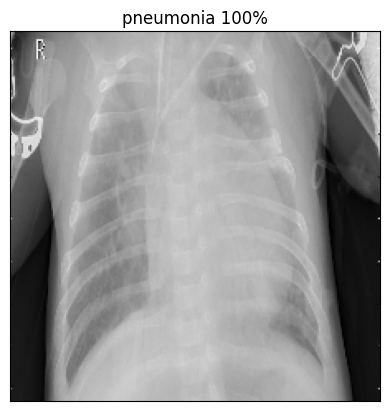

In [ ]:
plot_test_preds(custom_preds, custom_labels, custom_images, 0)